
Missing sensors: 4/32 (12.5%)
Linear RMSE: 0.00553340
Spline RMSE: 0.00155792

Missing sensors: 8/32 (25.0%)
Linear RMSE: 0.00413643
Spline RMSE: 0.00110457

Missing sensors: 12/32 (37.5%)
Linear RMSE: 0.00411152
Spline RMSE: 0.00105356


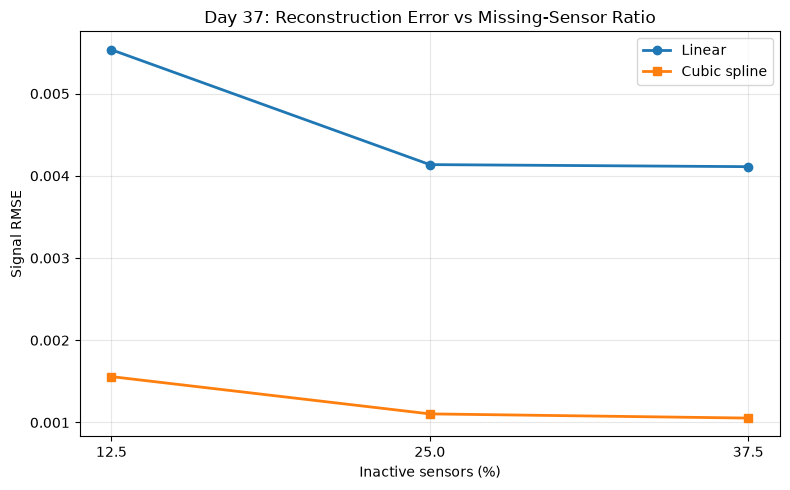

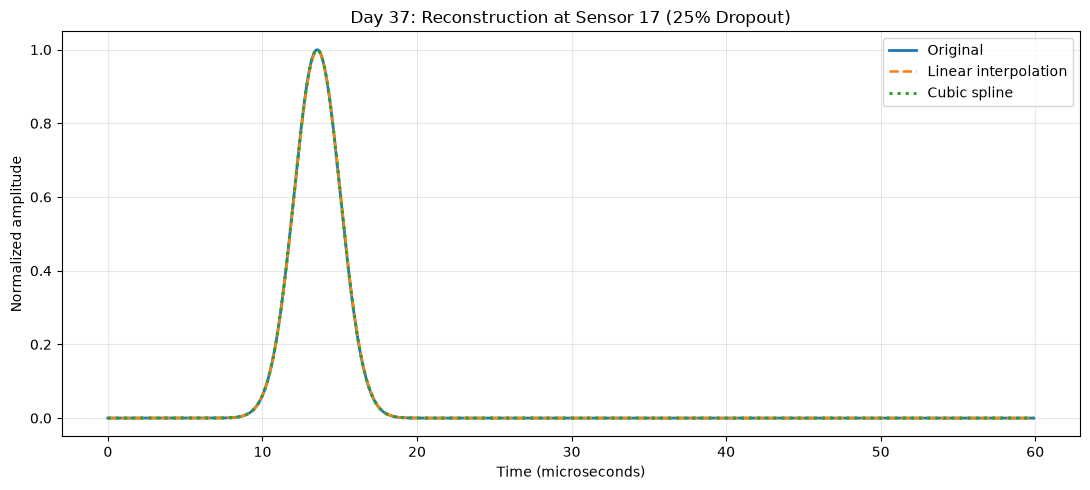


Day 37 completed.
RMSE plot: ..\outputs\day37_spline_rmse_vs_missing_ratio.png
Signal plot: ..\outputs\day37_spline_reconstruction_comparison.png
JSON results: ..\outputs\day37_spline_missing_ratio_results.json


In [1]:

import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d, CubicSpline

# ==========================================
# Day 37: Spline vs Linear at Different
# Missing-Sensor Ratios
# ==========================================

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Simulation parameters
num_sensors = 32
num_samples = 600

fs = 10e6
c = 1500.0
source_x = 5e-3
source_y = 20e-3
pulse_width = 1.5e-6

time = np.arange(num_samples) / fs
sensor_x = np.linspace(-15e-3, 15e-3, num_sensors)

# 2. Generate the original synthetic signals
signals_full = np.zeros((num_sensors, num_samples))

for i, sx in enumerate(sensor_x):
    distance = np.sqrt((sx - source_x)**2 + source_y**2)
    arrival_time = distance / c

    signals_full[i] = np.exp(
        -0.5 * ((time - arrival_time) / pulse_width)**2
    )

# 3. Use fixed, evenly distributed failure patterns.
# Keeping the patterns nested helps make the ratios comparable.
missing_counts = [4, 8, 12]
base_pattern = np.array(
    [1, 5, 9, 13, 17, 21, 25, 29]
)

# Add further sensors for the 12-sensor experiment.
extra_indices = np.array([3, 11, 19, 27])

results = {
    "day": 37,
    "method_comparison": ["linear", "cubic_spline"],
    "num_sensors": num_sensors,
    "missing_sensor_counts": {},
    "evaluation_region": "inactive sensor signals only"
}

rmse_by_method = {
    "Linear": [],
    "Cubic spline": []
}

mae_by_method = {
    "Linear": [],
    "Cubic spline": []
}

reconstruction_for_plot = {}

# 4. Test each missing-sensor ratio
for count in missing_counts:

    if count == 4:
        inactive_indices = base_pattern[:4]
    elif count == 8:
        inactive_indices = base_pattern
    else:
        inactive_indices = np.sort(
            np.concatenate([base_pattern, extra_indices])
        )

    active_mask = np.ones(num_sensors, dtype=bool)
    active_mask[inactive_indices] = False

    active_x = sensor_x[active_mask]
    active_signals = signals_full[active_mask]

    # Linear interpolation
    linear_interp = interp1d(
        active_x,
        active_signals,
        axis=0,
        kind="linear",
        bounds_error=False,
        fill_value="extrapolate"
    )

    signals_linear = signals_full.copy()
    signals_linear[inactive_indices] = linear_interp(
        sensor_x[inactive_indices]
    )

    # Cubic spline interpolation
    spline_interp = CubicSpline(
        active_x,
        active_signals,
        axis=0,
        bc_type="natural",
        extrapolate=True
    )

    signals_spline = signals_full.copy()
    signals_spline[inactive_indices] = spline_interp(
        sensor_x[inactive_indices]
    )

    # Evaluate only at missing sensors
    true_missing = signals_full[inactive_indices]

    linear_error = (
        signals_linear[inactive_indices] - true_missing
    )
    spline_error = (
        signals_spline[inactive_indices] - true_missing
    )

    def metrics(error):
        return {
            "MAE": float(np.mean(np.abs(error))),
            "RMSE": float(np.sqrt(np.mean(error**2))),
            "maximum_absolute_error": float(
                np.max(np.abs(error))
            )
        }

    linear_metrics = metrics(linear_error)
    spline_metrics = metrics(spline_error)

    missing_percentage = 100 * count / num_sensors

    results["missing_sensor_counts"][str(count)] = {
        "missing_percentage": missing_percentage,
        "inactive_indices": inactive_indices.tolist(),
        "linear": linear_metrics,
        "cubic_spline": spline_metrics
    }

    rmse_by_method["Linear"].append(linear_metrics["RMSE"])
    rmse_by_method["Cubic spline"].append(spline_metrics["RMSE"])

    mae_by_method["Linear"].append(linear_metrics["MAE"])
    mae_by_method["Cubic spline"].append(spline_metrics["MAE"])

    # Save the 25% case for the signal plot
    if count == 8:
        reconstruction_for_plot = {
            "inactive_indices": inactive_indices,
            "linear": signals_linear,
            "spline": signals_spline
        }

    print(f"\nMissing sensors: {count}/{num_sensors} "
          f"({missing_percentage:.1f}%)")
    print(f"Linear RMSE: {linear_metrics['RMSE']:.8f}")
    print(f"Spline RMSE: {spline_metrics['RMSE']:.8f}")

# 5. Plot RMSE versus missing-sensor ratio
ratios = [
    100 * count / num_sensors
    for count in missing_counts
]

plt.figure(figsize=(8, 5))

plt.plot(
    ratios, rmse_by_method["Linear"],
    marker="o", linewidth=2, label="Linear"
)

plt.plot(
    ratios, rmse_by_method["Cubic spline"],
    marker="s", linewidth=2, label="Cubic spline"
)

plt.xlabel("Inactive sensors (%)")
plt.ylabel("Signal RMSE")
plt.title("Day 37: Reconstruction Error vs Missing-Sensor Ratio")
plt.xticks(ratios)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    output_dir / "day37_spline_rmse_vs_missing_ratio.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 6. Plot original and reconstructed signal at an inactive sensor
sensor_to_plot = 17

plt.figure(figsize=(11, 5))

plt.plot(
    time * 1e6,
    signals_full[sensor_to_plot],
    label="Original",
    linewidth=2
)

plt.plot(
    time * 1e6,
    reconstruction_for_plot["linear"][sensor_to_plot],
    "--",
    label="Linear interpolation",
    linewidth=1.8
)

plt.plot(
    time * 1e6,
    reconstruction_for_plot["spline"][sensor_to_plot],
    ":",
    label="Cubic spline",
    linewidth=2.2
)

plt.xlabel("Time (microseconds)")
plt.ylabel("Normalized amplitude")
plt.title("Day 37: Reconstruction at Sensor 17 (25% Dropout)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    output_dir / "day37_spline_reconstruction_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 7. Save results to JSON
results_path = output_dir / "day37_spline_missing_ratio_results.json"

with open(results_path, "w", encoding="utf-8") as f:
    json.dump(results, f, indent=4, ensure_ascii=False)

print("\nDay 37 completed.")
print(f"RMSE plot: {output_dir / 'day37_spline_rmse_vs_missing_ratio.png'}")
print(f"Signal plot: {output_dir / 'day37_spline_reconstruction_comparison.png'}")
print(f"JSON results: {results_path}")
